# Session 14 · Model Performance Evaluation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-14-model-performance-evaluation.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: optimisers on a difficult loss surface

gradient descent  lr=0.005  final point (0.781, 0.604)  loss 0.04867  steps to loss<0.01: not reached
momentum          lr=0.002  final point (0.997, 0.995)  loss 0.00001  steps to loss<0.01: 200
Adam              lr=0.05   final point (1.000, 0.999)  loss 0.00000  steps to loss<0.01: 265


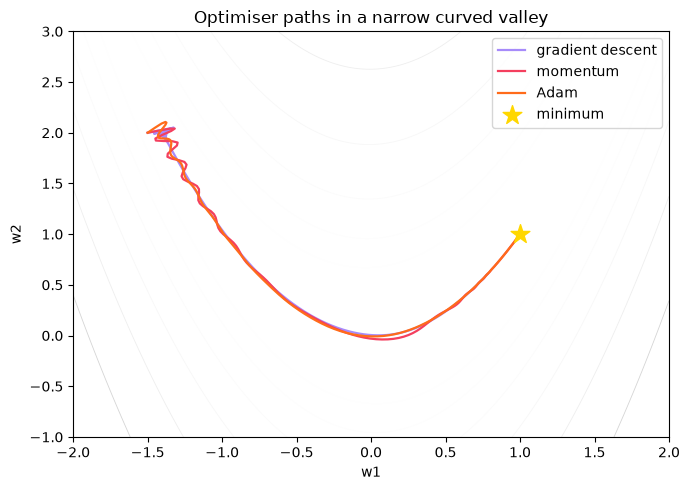

In [1]:
"""Compare gradient descent, momentum and Adam on an elongated valley (Rosenbrock-like) loss surface."""
import numpy as np
import matplotlib.pyplot as plt

def loss(w):            # a long, narrow, curved valley; minimum at (1, 1)
    x, y = w
    return (1 - x) ** 2 + 20 * (y - x ** 2) ** 2
def grad(w):
    x, y = w
    return np.array([-2 * (1 - x) - 80 * x * (y - x ** 2), 40 * (y - x ** 2)])

def run(method, lr, steps=600):
    w = np.array([-1.5, 2.0]); v = np.zeros(2); m = np.zeros(2); s = np.zeros(2); path = [w.copy()]
    for t in range(1, steps + 1):
        g = grad(w)
        if method == "gradient descent":
            w = w - lr * g
        elif method == "momentum":
            v = 0.9 * v + g; w = w - lr * v
        elif method == "Adam":
            m = 0.9 * m + 0.1 * g; s = 0.999 * s + 0.001 * g ** 2
            mh, sh = m / (1 - 0.9 ** t), s / (1 - 0.999 ** t)
            w = w - lr * mh / (np.sqrt(sh) + 1e-8)
        path.append(w.copy())
    return np.array(path)

configs = [("gradient descent", 0.005), ("momentum", 0.002), ("Adam", 0.05)]
xx, yy = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-1, 3, 200))
plt.figure(figsize=(7, 5))
plt.contour(xx, yy, (1 - xx) ** 2 + 20 * (yy - xx ** 2) ** 2, levels=np.logspace(-1, 3, 15), cmap="Greys", linewidths=.6)
for (name, lr), c in zip(configs, ["#A78BFA", "#F43F5E", "#FF6B1A"]):
    p = run(name, lr)
    print(f"{name:<17} lr={lr:<6} final point ({p[-1, 0]:.3f}, {p[-1, 1]:.3f})  loss {loss(p[-1]):.5f}  "
          f"steps to loss<0.01: {next((i for i, w in enumerate(p) if loss(w) < .01), 'not reached')}")
    plt.plot(p[:, 0], p[:, 1], color=c, lw=1.6, label=name)
plt.scatter([1], [1], marker="*", s=200, color="gold", zorder=5, label="minimum")
plt.legend(); plt.title("Optimiser paths in a narrow curved valley"); plt.xlabel("w1"); plt.ylabel("w2")
plt.tight_layout(); plt.savefig("session-14_optimisers.png", dpi=110); plt.show()

### Example 2 · Intermediate: Bayesian optimisation from scratch vs random search

In [2]:
"""Bayesian optimisation with a Gaussian-process surrogate and expected improvement, vs random search, tuning an SVM."""
import numpy as np
from scipy.stats import norm
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel

X, y = load_breast_cancer(return_X_y=True)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
def score(log_c, log_g):                       # the expensive black box we want to maximise
    model = make_pipeline(StandardScaler(), SVC(C=10 ** log_c, gamma=10 ** log_g))
    return cross_val_score(model, X, y, cv=cv).mean()
bounds = np.array([[-2, 3], [-5, 0]])          # log10 C, log10 gamma
rng = np.random.default_rng(0)
BUDGET = 15

# Random search
rand_pts = rng.uniform(bounds[:, 0], bounds[:, 1], (BUDGET, 2))
rand_scores = [score(*p) for p in rand_pts]

# Bayesian optimisation
pts = list(rng.uniform(bounds[:, 0], bounds[:, 1], (4, 2)))   # 4 random starting points
scores = [score(*p) for p in pts]
gp = GaussianProcessRegressor(Matern(nu=2.5) + WhiteKernel(1e-4), normalize_y=True, random_state=0)
while len(pts) < BUDGET:
    gp.fit(np.array(pts), np.array(scores))
    cand = rng.uniform(bounds[:, 0], bounds[:, 1], (2000, 2))
    mu, sd = gp.predict(cand, return_std=True)
    best = max(scores)
    z = (mu - best) / np.maximum(sd, 1e-9)
    ei = (mu - best) * norm.cdf(z) + sd * norm.pdf(z)          # expected improvement
    nxt = cand[np.argmax(ei)]
    pts.append(nxt); scores.append(score(*nxt))
    print(f"trial {len(pts):>2}: log10 C = {nxt[0]:5.2f}, log10 gamma = {nxt[1]:5.2f} -> CV accuracy {scores[-1]:.4f}")

print(f"\nbest after {BUDGET} trials | random search: {max(rand_scores):.4f} | Bayesian optimisation: {max(scores):.4f}")
print("best-so-far curve (random):  ", np.round(np.maximum.accumulate(rand_scores)[[3, 7, 11, 14]], 4))
print("best-so-far curve (Bayesian):", np.round(np.maximum.accumulate(scores)[[3, 7, 11, 14]], 4))

trial  5: log10 C =  1.42, log10 gamma = -3.16 -> CV accuracy 0.9736
trial  6: log10 C =  1.75, log10 gamma = -2.76 -> CV accuracy 0.9789
trial  7: log10 C =  1.37, log10 gamma = -2.60 -> CV accuracy 0.9824
trial  8: log10 C = -1.98, log10 gamma = -4.95 -> CV accuracy 0.6274


trial  9: log10 C = -1.93, log10 gamma = -0.01 -> CV accuracy 0.6274
trial 10: log10 C = -0.34, log10 gamma = -2.01 -> CV accuracy 0.9613
trial 11: log10 C =  2.94, log10 gamma = -0.32 -> CV accuracy 0.8418
trial 12: log10 C =  2.97, log10 gamma = -4.85 -> CV accuracy 0.9719
trial 13: log10 C =  2.99, log10 gamma = -3.56 -> CV accuracy 0.9807


trial 14: log10 C =  2.00, log10 gamma = -4.98 -> CV accuracy 0.9455
trial 15: log10 C =  2.70, log10 gamma = -4.06 -> CV accuracy 0.9772

best after 15 trials | random search: 0.9772 | Bayesian optimisation: 0.9824
best-so-far curve (random):   [0.9719 0.9719 0.9772 0.9772]
best-so-far curve (Bayesian): [0.9772 0.9824 0.9824 0.9824]


### Example 3 · Intermediate: every classification metric on an imbalanced problem

In [3]:
"""Accuracy trap, confusion matrix, precision/recall/F1, ROC AUC vs PR AUC, log loss and MCC on 3% fraud."""
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, log_loss, matthews_corrcoef, confusion_matrix)

X, y = make_classification(n_samples=20000, n_features=12, n_informative=6, weights=[.97], flip_y=.01, random_state=4)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.3, stratify=y, random_state=0)
print(f"fraud rate in test set: {y_te.mean():.3%}")

models = {"always 'not fraud'": DummyClassifier(strategy="most_frequent"),
          "logistic regression": LogisticRegression(max_iter=1000),
          "gradient boosting": HistGradientBoostingClassifier(random_state=0)}
print(f"\n{'model':<21}{'acc':>6}{'prec':>6}{'rec':>6}{'F1':>6}{'ROC':>6}{'PR AUC':>8}{'logloss':>8}{'MCC':>6}")
for name, m in models.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]; pred = (p >= .5).astype(int)
    print(f"{name:<21}{accuracy_score(y_te, pred):>6.3f}{precision_score(y_te, pred, zero_division=0):>6.2f}"
          f"{recall_score(y_te, pred):>6.2f}{f1_score(y_te, pred):>6.2f}{roc_auc_score(y_te, p):>6.2f}"
          f"{average_precision_score(y_te, p):>8.2f}{log_loss(y_te, p):>8.3f}{matthews_corrcoef(y_te, pred):>6.2f}")

gb = models["gradient boosting"]; p = gb.predict_proba(X_te)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_te, p >= .5).ravel()
print(f"\nconfusion matrix at 0.5 -> TP {tp}, FN {fn}, FP {fp}, TN {tn}")
for t in [.5, .3, .1]:
    pred = p >= t
    print(f"threshold {t:<4}: precision {precision_score(y_te, pred):.2f}  recall {recall_score(y_te, pred):.2f}  F1 {f1_score(y_te, pred):.2f}")

fraud rate in test set: 3.600%

model                   acc  prec   rec    F1   ROC  PR AUC logloss   MCC
always 'not fraud'    0.964  0.00  0.00  0.00  0.50    0.04   1.298  0.00
logistic regression   0.974  0.96  0.30  0.46  0.78    0.51   0.115  0.53


gradient boosting     0.982  0.91  0.54  0.68  0.89    0.71   0.074  0.70

confusion matrix at 0.5 -> TP 117, FN 99, FP 11, TN 5773
threshold 0.5 : precision 0.91  recall 0.54  F1 0.68
threshold 0.3 : precision 0.85  recall 0.60  F1 0.70
threshold 0.1 : precision 0.65  recall 0.68  F1 0.66


### Example 4 · Advanced: ROC, precision–recall and calibration curves

Naive Bayes                          ROC AUC 0.923  PR AUC 0.811  Brier 0.0639


Gradient boosting                    ROC AUC 0.972  PR AUC 0.942  Brier 0.0251
Naive Bayes + isotonic calibration   ROC AUC 0.922  PR AUC 0.804  Brier 0.0589


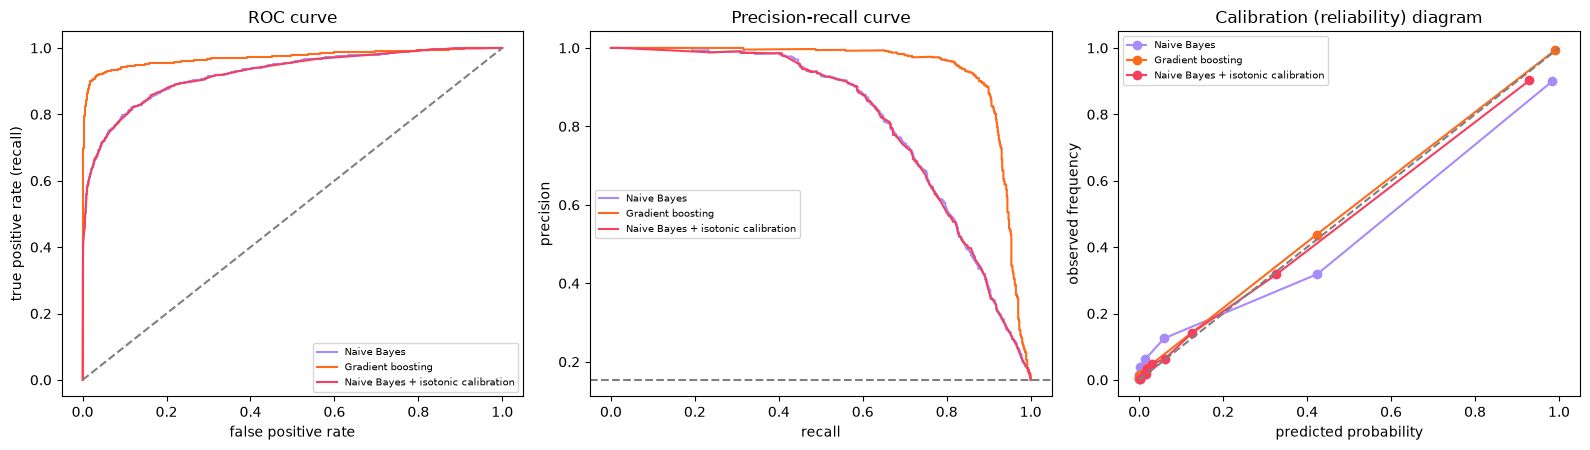

In [4]:
"""Plot ROC and precision-recall curves, and a calibration (reliability) diagram before and after calibration."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score, brier_score_loss

X, y = make_classification(n_samples=12000, n_features=15, n_informative=6, n_redundant=6, weights=[.85], random_state=1)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.4, stratify=y, random_state=0)
models = {"Naive Bayes": GaussianNB(), "Gradient boosting": HistGradientBoostingClassifier(random_state=0),
          "Naive Bayes + isotonic calibration": CalibratedClassifierCV(GaussianNB(), method="isotonic", cv=5)}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for (name, m), c in zip(models.items(), ["#A78BFA", "#FF6B1A", "#F43F5E"]):
    p = m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, p); prec, rec, _ = precision_recall_curve(y_te, p)
    frac, mean_p = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    print(f"{name:<36} ROC AUC {roc_auc_score(y_te, p):.3f}  PR AUC {average_precision_score(y_te, p):.3f}  Brier {brier_score_loss(y_te, p):.4f}")
    ax[0].plot(fpr, tpr, color=c, label=name); ax[1].plot(rec, prec, color=c, label=name)
    ax[2].plot(mean_p, frac, "o-", color=c, label=name)
ax[0].plot([0, 1], [0, 1], "--", color="grey"); ax[0].set_title("ROC curve"); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate (recall)")
ax[1].axhline(y_te.mean(), ls="--", color="grey"); ax[1].set_title("Precision-recall curve"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision")
ax[2].plot([0, 1], [0, 1], "--", color="grey"); ax[2].set_title("Calibration (reliability) diagram"); ax[2].set_xlabel("predicted probability"); ax[2].set_ylabel("observed frequency")
for a in ax: a.legend(fontsize=7)
fig.tight_layout(); fig.savefig("session-14_evaluation_curves.png", dpi=100); plt.show()

### Example 5 · Advanced: the right cross-validation scheme (group leakage)

In [5]:
"""Leakage demo: several rows per patient. Plain KFold over-estimates accuracy; GroupKFold gives the honest number."""
import numpy as np
from sklearn.model_selection import KFold, GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

rng = np.random.default_rng(0)
patients, visits = 200, 6
pid = np.repeat(np.arange(patients), visits)
signature = rng.normal(0, 1, (patients, 8))[pid]                 # each patient has a personal 'fingerprint'
X = signature + rng.normal(0, .3, (len(pid), 8))
risk = rng.random(patients) < .5
y = risk[pid].astype(int)
X[:, 0] += 0.4 * y + rng.normal(0, 1, len(y))                    # only a weak real signal

rf = RandomForestClassifier(200, random_state=0, n_jobs=-1)
plain = cross_val_score(rf, X, y, cv=KFold(5, shuffle=True, random_state=0)).mean()
grouped = cross_val_score(rf, X, y, cv=GroupKFold(5), groups=pid).mean()
print(f"KFold (visits of the same patient in train and test): {plain:.3f}  <- optimistic, memorises patients")
print(f"GroupKFold (each patient only in one fold)          : {grouped:.3f}  <- what you get for NEW patients")

KFold (visits of the same patient in train and test): 0.806  <- optimistic, memorises patients
GroupKFold (each patient only in one fold)          : 0.472  <- what you get for NEW patients


### 🏙️ Real-life data problem: a hospital readmission model that the ward can trust

In [6]:
"""Real-life problem: readmission risk model tuned on PR AUC, judged by recall@capacity and calibration."""
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

rng = np.random.default_rng(30)
n = 8000
df = pd.DataFrame({"age": rng.integers(18, 95, n), "length_of_stay": rng.gamma(2, 2.5, n).round(),
                   "prior_admissions": rng.poisson(.8, n), "num_medications": rng.poisson(6, n),
                   "chronic_conditions": rng.poisson(1.5, n), "lives_alone": rng.random(n) < .25,
                   "follow_up_booked": rng.random(n) < .6, "abnormal_labs": rng.poisson(1, n)})
z = (-3.4 + .02 * (df.age - 50) + .08 * df.length_of_stay + .55 * df.prior_admissions + .05 * df.num_medications
     + .25 * df.chronic_conditions + .5 * df.lives_alone - .7 * df.follow_up_booked + .2 * df.abnormal_labs
     + .4 * (df.prior_admissions >= 2) * df.lives_alone)
df["readmitted"] = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
X, y = df.drop(columns="readmitted").astype(float), df["readmitted"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25, stratify=y, random_state=0)
print(f"readmission rate: {y.mean():.1%} | train {len(X_tr)} | locked test {len(X_te)}")

cv = StratifiedKFold(5, shuffle=True, random_state=0)
searches = {
    "logistic regression": RandomizedSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        {"logisticregression__C": loguniform(1e-3, 1e2)}, n_iter=12, cv=cv, scoring="average_precision", random_state=0),
    "gradient boosting": RandomizedSearchCV(HistGradientBoostingClassifier(random_state=0),
        {"learning_rate": loguniform(.02, .3), "max_depth": [2, 3, 4, None], "max_iter": randint(100, 500),
         "l2_regularization": loguniform(1e-3, 10)}, n_iter=12, cv=cv, scoring="average_precision", random_state=0),
}
CAP = 0.10
def recall_at_capacity(y_true, p, cap=CAP):
    top = np.argsort(-p)[: int(len(p) * cap)]
    return y_true.values[top].sum() / y_true.sum()

print(f"\n{'model':<22}{'CV PR AUC':>10}{'test PR AUC':>12}{'ROC AUC':>9}{'recall@top10%':>15}{'Brier':>8}")
for name, s in searches.items():
    s.fit(X_tr, y_tr); p = s.predict_proba(X_te)[:, 1]
    print(f"{name:<22}{s.best_score_:>10.3f}{average_precision_score(y_te, p):>12.3f}{roc_auc_score(y_te, p):>9.3f}"
          f"{recall_at_capacity(y_te, p):>15.1%}{brier_score_loss(y_te, p):>8.4f}")

best = max(searches, key=lambda k: searches[k].best_score_)
cal = CalibratedClassifierCV(searches[best].best_estimator_, method="isotonic", cv=5).fit(X_tr, y_tr)
p = cal.predict_proba(X_te)[:, 1]
threshold = np.quantile(p, 1 - CAP)
print(f"\nchosen model: {best} (+ isotonic calibration) | Brier {brier_score_loss(y_te, p):.4f}")
print(f"operating threshold for 100 calls per 1,000 discharges: risk >= {threshold:.2f}")
flagged = p >= threshold
print(f"patients flagged: {flagged.mean():.1%} | precision among calls: {y_te[flagged].mean():.1%} "
      f"(base rate {y_te.mean():.1%}) | readmissions caught: {y_te[flagged].sum() / y_te.sum():.1%}")
bins = pd.cut(p, [0, .05, .1, .2, .3, 1])
print("\ncalibration check on the test set (predicted vs observed):")
print(pd.DataFrame({"predicted": p, "observed": y_te.values}).groupby(bins, observed=True).mean().round(3).to_string())

readmission rate: 17.2% | train 6000 | locked test 2000

model                  CV PR AUC test PR AUC  ROC AUC  recall@top10%   Brier


logistic regression        0.394       0.406    0.738          26.2%  0.1251


gradient boosting          0.381       0.372    0.718          23.8%  0.1287

chosen model: logistic regression (+ isotonic calibration) | Brier 0.1258
operating threshold for 100 calls per 1,000 discharges: risk >= 0.34
patients flagged: 10.2% | precision among calls: 44.4% (base rate 17.2%) | readmissions caught: 26.5%

calibration check on the test set (predicted vs observed):
             predicted  observed
(0.0, 0.05]      0.035     0.025
(0.05, 0.1]      0.081     0.087
(0.1, 0.2]       0.151     0.167
(0.2, 0.3]       0.253     0.258
(0.3, 1.0]       0.463     0.419


### 🧩 Mini project: a reusable model evaluation report

In [7]:
"""Mini project: a function that produces a complete evaluation report for any fitted binary classifier."""
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, log_loss)

def evaluation_report(name, model, X_te, y_te, threshold=0.5, positive="malignant"):
    p = model.predict_proba(X_te)[:, 1]; pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    lines = [f"=== {name} (threshold {threshold}) ===",
             f"confusion matrix: TP={tp} FP={fp} FN={fn} TN={tn}",
             f"precision {precision_score(y_te, pred):.3f} | recall {recall_score(y_te, pred):.3f} | F1 {f1_score(y_te, pred):.3f}",
             f"ROC AUC {roc_auc_score(y_te, p):.3f} | PR AUC {average_precision_score(y_te, p):.3f}",
             f"log loss {log_loss(y_te, p):.3f} | Brier {brier_score_loss(y_te, p):.4f}",
             f"plain-language: of {tp + fn} {positive} cases, the model caught {tp} and missed {fn}; it raised {fp} false alarms."]
    return "\n".join(lines)

X, y = load_breast_cancer(return_X_y=True)
y = 1 - y                                         # make 1 = malignant (the class we must not miss)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.3, stratify=y, random_state=0)
models = {"logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "random forest": RandomForestClassifier(300, random_state=0, n_jobs=-1)}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    print(evaluation_report(name, m, X_te, y_te))
    print(evaluation_report(name, m, X_te, y_te, threshold=0.2).split("\n", 1)[1].split("\n")[-1], "(threshold 0.2)\n")

=== logistic regression (threshold 0.5) ===
confusion matrix: TP=60 FP=4 FN=4 TN=103
precision 0.938 | recall 0.938 | F1 0.938
ROC AUC 0.992 | PR AUC 0.989
log loss 0.107 | Brier 0.0326
plain-language: of 64 malignant cases, the model caught 60 and missed 4; it raised 4 false alarms.


plain-language: of 64 malignant cases, the model caught 61 and missed 3; it raised 13 false alarms. (threshold 0.2)



=== random forest (threshold 0.5) ===
confusion matrix: TP=60 FP=6 FN=4 TN=101
precision 0.909 | recall 0.938 | F1 0.923
ROC AUC 0.980 | PR AUC 0.980
log loss 0.334 | Brier 0.0414
plain-language: of 64 malignant cases, the model caught 60 and missed 4; it raised 6 false alarms.
plain-language: of 64 malignant cases, the model caught 62 and missed 2; it raised 20 false alarms. (threshold 0.2)

